# Adaptive training of reservoir type ONN



In [1]:
from pathlib import Path
from utils.datasets import flat_result_path, flat_result_directory
from datetime import datetime, timezone, timedelta

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import solve
from scipy.interpolate import PchipInterpolator
from threadpoolctl import threadpool_limits
from IPython.display import display
from utils.experimental_analysis import _manifest, _indices, _find, _matlab_text

ROOT = Path.cwd()
DATA = ROOT / 'experimental_results/fmnist/long_term'
OUTPUT = ROOT / 'results/simulation/reservoir_adaptive_training'
flat_result_directory(OUTPUT).mkdir(parents=True, exist_ok=True)


## 1. Load experimental data



In [2]:
def recorded_time(path):
    with h5py.File(path, 'r') as f:
        stamp = _matlab_text(f['provenance/run_id'][()]).rsplit('_', 1)[-1]
    return datetime.strptime(stamp[:15], '%Y%m%dT%H%M%S').replace(
        tzinfo=timezone(timedelta(hours=8)))

measurement_files = sorted(DATA.glob('*.mat'), key=recorded_time)
times = [recorded_time(path) for path in measurement_files]
days = np.array([(time - times[0]).total_seconds() / 86400 for time in times])
# Refit at the first session and the four recovery events shown in the figure.
fit_sessions = np.array([0, 5, 8, 12, 16])

with h5py.File(DATA / 'sim_source_data/source.mat', 'r') as f:
    blocks = _manifest(f)
    support_block = _find([b for b in blocks if int(b['ipc']) == 5], block_type='support')
    support_indices = _indices(support_block)
    test_indices = _indices(_find(blocks, block_type='test'))
    targets = np.asarray(f['all_label_soft'], dtype=np.float64).T[support_indices]
    all_labels = np.asarray(f['all_label_hard'], dtype=np.int64).reshape(-1)
    test_labels = all_labels[test_indices]
ridge_lambda = float(support_block['ridge_beta'])

def load_measurement(path):
    with h5py.File(path, 'r') as f:
        # Original camera output: 32 x 32 channels x 10,180 input patterns.
        output = np.asarray(f['output'], dtype=np.float64)
    return output.reshape(1024, len(all_labels)).T

assert len(measurement_files) == 17
support_features = np.stack([load_measurement(measurement_files[i])[support_indices]
                             for i in fit_sessions])
assert support_features.shape == (5, 50, 1024)
assert targets.shape == (50, 10) and test_labels.shape == (10000,)


## 2. Retrain the readout


In [3]:
readouts = []
with threadpool_limits(limits=2):
    for features in support_features:
        z = features / features.max()
        weights = z.T @ solve(
            z @ z.T + ridge_lambda * np.eye(len(z)), targets, assume_a='pos')
        readouts.append(weights)
readouts = np.stack(readouts)


## 3. Evaluate accuracy



In [4]:
accuracy = np.full((len(fit_sessions), len(times)), np.nan)
with threadpool_limits(limits=2):
    for session in range(len(times)):
        test = load_measurement(measurement_files[session])[test_indices]
        test = test / test.max()
        for model, start in enumerate(fit_sessions):
            end = fit_sessions[model + 1] if model + 1 < len(fit_sessions) else start
            if start <= session <= end:
                prediction = (test @ readouts[model]).argmax(axis=1)
                accuracy[model, session] = 100 * np.mean(prediction == test_labels)

recovery = pd.DataFrame([
    {'Retraining time (UTC+08)': times[session].strftime('%m-%d %H:%M'),
     'Before (%)': accuracy[model, session],
     'After (%)': accuracy[model + 1, session]}
    for model, session in enumerate(fit_sessions[1:])
])
np.savez_compressed(
    flat_result_path(OUTPUT / 'results.npz'), days=days, accuracy_pct=accuracy,
    fit_session_indices=fit_sessions, readouts=readouts,
    timestamps=np.array([time.isoformat() for time in times]), ridge_lambda=ridge_lambda)
session_accuracy = pd.DataFrame([
    {'Readout': f'W{model + 1}',
     'Measurement time (UTC+08)': times[session].strftime('%m-%d %H:%M'),
     'Elapsed days': days[session],
     'Accuracy (%)': accuracy[model, session]}
    for model in range(len(fit_sessions))
    for session in range(len(times))
    if np.isfinite(accuracy[model, session])
])
display(session_accuracy.round({'Elapsed days': 2, 'Accuracy (%)': 2}))
display(recovery.round(2))


,Readout,Measurement time (UTC+08),Elapsed days,Accuracy (%)
0,W1,09-12 00:03,0.0,82.52
1,W1,09-12 12:02,0.5,80.41
2,W1,09-13 00:02,1.0,78.06
3,W1,09-13 12:01,1.5,66.92
4,W1,09-14 00:02,2.0,23.97
5,W1,09-14 12:02,2.5,14.04
6,W2,09-14 12:02,2.5,82.75
7,W2,09-15 00:01,3.0,79.93
8,W2,09-16 00:01,4.0,36.75
9,W2,09-16 12:02,4.5,32.43


,Retraining time (UTC+08),Before (%),After (%)
0,09-14 12:02,14.04,82.75
1,09-16 12:02,32.43,82.42
2,09-19 12:01,10.88,82.86
3,09-22 00:05,30.54,82.36


## 4. Plot results


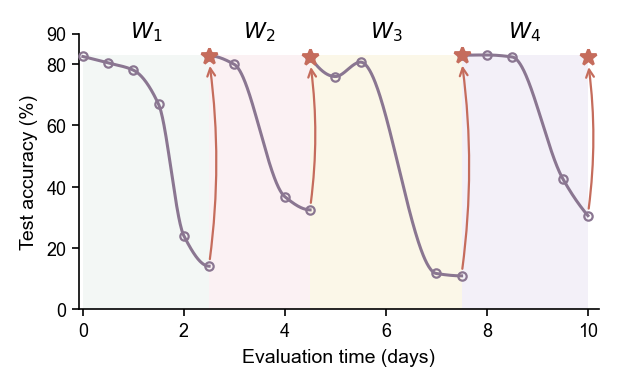

In [5]:
style = {
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
    'font.size': 7, 'axes.labelsize': 7, 'xtick.labelsize': 6.5,
    'ytick.labelsize': 6.5, 'axes.linewidth': 0.6, 'svg.fonttype': 'none',
}
with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=(80 / 25.4, 50 / 25.4), dpi=200)
    fig.subplots_adjust(left=0.15, right=0.975, bottom=0.20, top=0.90)
    purple, coral = '#8A7691', '#C56C5C'
    backgrounds = ['#F3F7F5', '#FBF1F3', '#FBF7E8', '#F3F0F8']
    for model, (start, end) in enumerate(zip(fit_sessions[:-1], fit_sessions[1:])):
        x = days[start:end + 1]
        y = accuracy[model, start:end + 1]
        ax.axvspan(x[0], x[-1], ymin=0, ymax=83 / 90,
                   color=backgrounds[model], lw=0, zorder=0)
        dense_x = np.linspace(x[0], x[-1], 250)
        ax.plot(dense_x, PchipInterpolator(x, y)(dense_x), color=purple, lw=1.1)
        ax.plot(x, y, ls='none', marker='o', ms=3.0, mfc='none',
                mec=purple, mew=0.8, zorder=3, clip_on=False)
        after = accuracy[model + 1, end]
        ax.annotate('', xy=(x[-1], after - 1.5), xytext=(x[-1], y[-1] + 0.5),
                    arrowprops=dict(arrowstyle='->', color=coral, lw=0.8,
                                    connectionstyle='arc3,rad=0.07'))
        ax.plot(x[-1], after, '*', color=coral, ms=6.0, zorder=4, clip_on=False)
        ax.text((x[0] + x[-1]) / 2, 87, rf'$W_{model + 1}$',
                ha='center', va='bottom', fontsize=8)

    ax.set(xlim=(-0.08, 10.21), ylim=(0, 90),
           xlabel='Evaluation time (days)', ylabel='Test accuracy (%)',
           xticks=np.arange(0, 11, 2), yticks=[0, 20, 40, 60, 80, 90])
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(direction='out', length=2.5, width=0.6, pad=2)
    ax.xaxis.labelpad = ax.yaxis.labelpad = 3
    plt.show()
